# EECE 490/690 – Applied Ensemble Learning: Random Forests and Boosting
**Dataset B – Heart Disease Prediction** · Member 2 section: Part 3 (Random Forest vs. boosting), Part 4 (class imbalance with SMOTENC)

Builds on Member 1's `shared_setup.py`: same split, same `CV` folds, same scoring, improved preprocessing.

## 0. Environment and shared setup

In [1]:
# In Colab, imbalanced-learn may need installing
%pip install -q imbalanced-learn xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sklearn, imblearn, xgboost
warnings.filterwarnings("ignore", category=UserWarning)

print("python", sys.version.split()[0])
for m in (sklearn, imblearn, xgboost, pd, np):
    print(m.__name__, m.__version__)

python 3.12.10
sklearn 1.9.1
imblearn 0.14.2
xgboost 3.4.1
pandas 3.1.0
numpy 2.5.4


In [3]:
from shared_setup import *   # SEED, CV, SCORING, NUM_COLS, CAT_COLS, load_and_split, build_preprocessor, build_numeric_pipeline, summarize_cv
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)

X_train, X_test, y_train, y_test = load_and_split("heart.csv")   # X_test / y_test are NOT used in this section
print("train:", X_train.shape, " test (locked):", X_test.shape)

train: (734, 11)  test (locked): (184, 11)


### 3.0 Protocol

- **Data:** training split only (734 rows × 11 features, cell above); the 184-row test set stays locked until Part 5.
- **Folds:** the shared `CV` object (stratified 3-fold, shuffled, `random_state=SEED`), so every model and every grid candidate is scored on identical partitions.
- **Preprocessing:** Member 1's `build_preprocessor("improved")` (zeros → NaN in RestingBP/Cholesterol, scaling, KNN imputation with a missingness indicator, one-hot encoding), placed *inside* each pipeline as the `"pre"` step so it is refit on every training fold.
- **Tuning budget:** two hyperparameters and six candidate settings per model: Random Forest `max_depth` {None, 5, 10} × `min_samples_leaf` {1, 5} (300 trees fixed); XGBoost `max_depth` {3, 5} × `learning_rate` {0.05, 0.1, 0.3} (200 rounds fixed). AdaBoost uses its defaults. Everything else is held fixed, so each comparison changes one factor.
- **Selection metric: ROC-AUC** (`refit="roc_auc"`). Recall on class 1 is the project's primary metric, but class 1 is the majority class here, so the majority-class Dummy already reaches recall 1.000 (table in 3.3): ranking by recall alone would reward degenerate models. ROC-AUC is threshold-independent and measures how well a model ranks sick above healthy patients; recall is reported next to it for every setting, and Part 5 can favour recall by moving the decision threshold.
- **Reporting:** `return_train_score=True` everywhere; tables show `train_*` / `val_*` as mean ± std over the 3 folds, in the same format as Member 1's `summarize_cv()`.

### 3.1 Random Forest – grid search (6 settings)

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_validate

# Same pipeline as Member 1's Part 2 RF (step names "pre"/"model", 300 trees) -> only max_depth / min_samples_leaf change
rf_pipe = Pipeline([
    ("pre", build_preprocessor("improved")),
    ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
])
rf_grid = {"model__max_depth": [None, 5, 10],      # 3 x 2 = 6 candidate settings
           "model__min_samples_leaf": [1, 5]}

rf_search = GridSearchCV(rf_pipe, rf_grid, cv=CV, scoring=SCORING,
                         refit="roc_auc",            # selection metric (recall alone is maxed by the dummy)
                         return_train_score=True)
rf_search.fit(X_train, y_train)                      # training data only; preprocessing refit inside every fold


def grid_table(search):
    """(a) One row per candidate, train_*/val_* as mean +/- std (same format as summarize_cv)."""
    res, rows = search.cv_results_, []
    for i, params in enumerate(res["params"]):
        row = {k.replace("model__", ""): str(v) for k, v in params.items()}
        for m in SCORING:
            for split, label in (("train", "train"), ("test", "val")):
                row[f"{label}_{m}"] = f"{res[f'mean_{split}_{m}'][i]:.3f} +/- {res[f'std_{split}_{m}'][i]:.3f}"
        row["rank_val_roc_auc"] = res["rank_test_roc_auc"][i]
        rows.append(row)
    return pd.DataFrame(rows).sort_values("rank_val_roc_auc").reset_index(drop=True)


rf_grid_table = grid_table(rf_search)
display(rf_grid_table)

# (b) Best setting re-scored with cross_validate on the same CV folds -> row in Member 1's exact format
print("Best RF params:", rf_search.best_params_, "| mean val ROC-AUC:", round(rf_search.best_score_, 3))
rf_best_cv = cross_validate(rf_search.best_estimator_, X_train, y_train, cv=CV,
                            scoring=SCORING, return_train_score=True)
rf_best_row = pd.DataFrame([summarize_cv(rf_best_cv, "RandomForest (tuned)")]).set_index("model")
rf_best_row

,max_depth,min_samples_leaf,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc,rank_val_roc_auc
0,10,5,0.907 +/- 0.007,0.860 +/- 0.021,0.893 +/- 0.005,0.848 +/- 0.009,0.945 +/- 0.011,0.909 +/- 0.033,0.918 +/- 0.006,0.877 +/- 0.020,0.973 +/- 0.002,0.932 +/- 0.013,1
1,None,5,0.908 +/- 0.008,0.861 +/- 0.020,0.896 +/- 0.004,0.850 +/- 0.007,0.943 +/- 0.011,0.909 +/- 0.033,0.919 +/- 0.007,0.878 +/- 0.019,0.974 +/- 0.002,0.932 +/- 0.013,2
2,5,1,0.911 +/- 0.006,0.865 +/- 0.020,0.902 +/- 0.006,0.856 +/- 0.006,0.942 +/- 0.010,0.909 +/- 0.040,0.922 +/- 0.005,0.881 +/- 0.020,0.973 +/- 0.002,0.932 +/- 0.014,3
3,5,5,0.896 +/- 0.006,0.861 +/- 0.020,0.885 +/- 0.001,0.850 +/- 0.007,0.932 +/- 0.011,0.909 +/- 0.033,0.908 +/- 0.005,0.878 +/- 0.019,0.962 +/- 0.003,0.932 +/- 0.015,4
4,10,1,0.995 +/- 0.003,0.850 +/- 0.010,0.991 +/- 0.006,0.847 +/- 0.016,1.000 +/- 0.000,0.892 +/- 0.043,0.996 +/- 0.003,0.868 +/- 0.013,1.000 +/- 0.000,0.930 +/- 0.014,5
5,None,1,1.000 +/- 0.000,0.862 +/- 0.013,1.000 +/- 0.000,0.856 +/- 0.011,1.000 +/- 0.000,0.904 +/- 0.040,1.000 +/- 0.000,0.879 +/- 0.015,1.000 +/- 0.000,0.930 +/- 0.012,6


Best RF params: {'model__max_depth': 10, 'model__min_samples_leaf': 5} | mean val ROC-AUC: 0.932


,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc
model,,,,,,,,,,
RandomForest (tuned),0.907 +/- 0.007,0.860 +/- 0.021,0.893 +/- 0.005,0.848 +/- 0.009,0.945 +/- 0.011,0.909 +/- 0.033,0.918 +/- 0.006,0.877 +/- 0.020,0.973 +/- 0.002,0.932 +/- 0.013


**Reading the Random Forest grid** (all numbers: mean over the 3 shared CV folds, training data only)

- **Sanity check.** The untuned setting `max_depth=None, min_samples_leaf=1` reproduces Member 1's improved-pipeline RF exactly (val accuracy 0.862, precision 0.856, recall 0.904, F1 0.879, ROC-AUC 0.930), so our pipeline and folds match Part 2.
- **Validation is flat.** Validation ROC-AUC lies between 0.930 and 0.932 across all six settings, so on this dataset the forest is insensitive to these two hyperparameters.
- **The difference is in the train–validation gap.** With `min_samples_leaf=1` and `max_depth` None or 10, train ROC-AUC is 1.000 (gap ≈ 0.07): the trees memorise the training folds. *Either* limit reduces this: shallower trees (`max_depth=5, min_samples_leaf=1`: train 0.973, gap ≈ 0.04) or bigger leaves (`min_samples_leaf=5`: gap ≈ 0.04 at depth None/10, 0.030 at depth 5). Validation ROC-AUC stays essentially the same (0.932 vs 0.930, well inside the fold std).
- **Why the overfit forests still validate well.** Each fully grown tree has low bias but high variance. Bootstrap samples and random feature subsets make the trees' errors partly independent, so averaging 300 of them cancels much of that variance. Bagging tolerates overfit base learners.
- **Recall (primary metric).** Validation recall is 0.909 for the top four settings, 0.904 for None / 1, and lowest for 10 / 1 (0.892). No setting trades recall for ROC-AUC in a meaningful way.
- **Selected setting.** Refit on ROC-AUC picks `max_depth=10, min_samples_leaf=5` (val ROC-AUC 0.932 ± 0.013, val recall 0.909 ± 0.033). However, the top four settings tie at 0.932 and the fold std is ≈ 0.013, so this is a statistical tie, not a clear winner; we keep it as a mildly regularised forest. The setting was also chosen on the same folds it is scored on (and the `cross_validate` row reuses those folds), so 0.932 is slightly optimistic; the unbiased estimate comes from the single test-set evaluation in Part 5.
- **Did extra complexity help?** No. Unrestricted trees reached train ROC-AUC 1.000 but validation 0.930, no better than the restricted settings.

### 3.2 XGBoost – grid search (6 settings)

In [5]:
from xgboost import XGBClassifier

# Same "pre" step and folds as the RF grid; n_estimators fixed at 200 -> only max_depth / learning_rate change
xgb_pipe = Pipeline([
    ("pre", build_preprocessor("improved")),
    ("model", XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=SEED, n_jobs=-1)),
])
xgb_grid = {"model__max_depth": [3, 5],                 # 2 x 3 = 6 candidate settings
            "model__learning_rate": [0.05, 0.1, 0.3]}

xgb_search = GridSearchCV(xgb_pipe, xgb_grid, cv=CV, scoring=SCORING,
                          refit="roc_auc", return_train_score=True)
xgb_search.fit(X_train, y_train)                        # training data only

xgb_grid_table = grid_table(xgb_search)                 # (a) same helper as 3.1
display(xgb_grid_table)

# (b) best setting re-scored on the same folds, Member 1's row format
print("Best XGB params:", xgb_search.best_params_, "| mean val ROC-AUC:", round(xgb_search.best_score_, 3))
xgb_best_cv = cross_validate(xgb_search.best_estimator_, X_train, y_train, cv=CV,
                             scoring=SCORING, return_train_score=True)
xgb_best_row = pd.DataFrame([summarize_cv(xgb_best_cv, "XGBoost (tuned)")]).set_index("model")
xgb_best_row

,learning_rate,max_depth,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc,rank_val_roc_auc
0,0.05,3,0.950 +/- 0.003,0.862 +/- 0.008,0.948 +/- 0.005,0.863 +/- 0.020,0.962 +/- 0.011,0.894 +/- 0.033,0.955 +/- 0.003,0.878 +/- 0.009,0.990 +/- 0.002,0.929 +/- 0.006,1
1,0.1,3,0.984 +/- 0.005,0.858 +/- 0.010,0.982 +/- 0.008,0.861 +/- 0.009,0.989 +/- 0.003,0.887 +/- 0.024,0.985 +/- 0.004,0.874 +/- 0.011,0.999 +/- 0.001,0.922 +/- 0.004,2
2,0.1,5,1.000 +/- 0.000,0.845 +/- 0.007,1.000 +/- 0.000,0.841 +/- 0.009,1.000 +/- 0.000,0.887 +/- 0.015,1.000 +/- 0.000,0.863 +/- 0.007,1.000 +/- 0.000,0.921 +/- 0.006,3
3,0.05,5,0.996 +/- 0.003,0.850 +/- 0.002,0.993 +/- 0.005,0.846 +/- 0.008,1.000 +/- 0.000,0.892 +/- 0.009,0.996 +/- 0.003,0.868 +/- 0.001,1.000 +/- 0.000,0.919 +/- 0.006,4
4,0.3,5,1.000 +/- 0.000,0.856 +/- 0.002,1.000 +/- 0.000,0.856 +/- 0.009,1.000 +/- 0.000,0.889 +/- 0.016,1.000 +/- 0.000,0.872 +/- 0.003,1.000 +/- 0.000,0.919 +/- 0.011,5
5,0.3,3,1.000 +/- 0.000,0.862 +/- 0.015,1.000 +/- 0.000,0.860 +/- 0.010,1.000 +/- 0.000,0.897 +/- 0.022,1.000 +/- 0.000,0.878 +/- 0.015,1.000 +/- 0.000,0.915 +/- 0.005,6


Best XGB params: {'model__learning_rate': 0.05, 'model__max_depth': 3} | mean val ROC-AUC: 0.929


,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc
model,,,,,,,,,,
XGBoost (tuned),0.950 +/- 0.003,0.862 +/- 0.008,0.948 +/- 0.005,0.863 +/- 0.020,0.962 +/- 0.011,0.894 +/- 0.033,0.955 +/- 0.003,0.878 +/- 0.009,0.990 +/- 0.002,0.929 +/- 0.006


**Reading the XGBoost grid** (mean over the 3 shared CV folds, training data only)

- **Only the gentlest setting avoids memorising the training folds.** With `learning_rate=0.05, max_depth=3`, train ROC-AUC is 0.990; `0.1 / 3` already reaches 0.999 and the other four settings reach 1.000. The gentlest setting is also the one that validates best (val ROC-AUC 0.929 ± 0.006), while the most aggressive learning rate gives the lowest validation score (`0.3 / 3`: 0.915 ± 0.005). Unlike the forest, here overfitting the training folds *does* cost validation performance: each boosting round fits the previous rounds' residual errors, so with a large step size or deep trees the later rounds start fitting noise, and nothing averages it away.
- **Larger spread than Random Forest, but not conclusive.** Validation ROC-AUC ranges from 0.915 to 0.929 (a spread of 0.014, versus 0.930–0.932 for RF), and the fold std of each setting is 0.004–0.011. The ordering is consistent with the overfitting story, but with only 3 folds the differences between neighbouring settings are within noise.
- **Recall.** Validation recall stays between 0.887 and 0.897 for all six settings; the selected setting has 0.894 ± 0.033.
- **Selected setting and limitation.** Refit on ROC-AUC picks `learning_rate=0.05, max_depth=3`. This is at the *edge* of the grid (smallest learning rate, shallowest trees), so an even gentler setting (or more rounds at a smaller rate) might score higher. We do not expand the grid: the assignment limits tuning to six candidate settings, so we report this as a limitation.
- **Same-folds caveat.** As for RF, the setting was chosen on the same folds it is scored on (and the `cross_validate` row reuses those folds), so 0.929 is slightly optimistic; the unbiased estimate comes from the single test-set evaluation in Part 5.

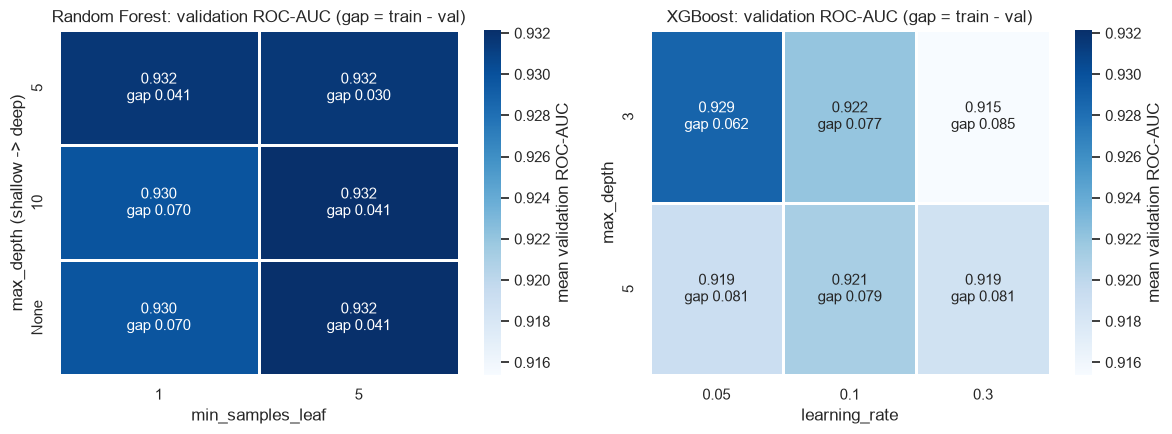

In [6]:
# Validation ROC-AUC per grid cell (colour) + train-minus-validation gap (annotation), both grids on one colour scale
def grid_matrix(search, row_param, col_param, row_order, col_order):
    # str() on each raw param value, so max_depth=None becomes "None" (a DataFrame would turn it into NaN)
    res = pd.DataFrame([{k.replace("model__", ""): str(v) for k, v in p.items()} for p in search.cv_results_["params"]])
    res["val"] = search.cv_results_["mean_test_roc_auc"]
    res["gap"] = search.cv_results_["mean_train_roc_auc"] - res["val"]
    val = res.pivot(index=row_param, columns=col_param, values="val").loc[row_order, col_order]
    gap = res.pivot(index=row_param, columns=col_param, values="gap").loc[row_order, col_order]
    annot = val.map(lambda v: f"{v:.3f}") + "\ngap " + gap.map(lambda g: f"{g:.3f}")
    return val, annot

rf_val, rf_annot = grid_matrix(rf_search, "max_depth", "min_samples_leaf", ["5", "10", "None"], ["1", "5"])
xgb_val, xgb_annot = grid_matrix(xgb_search, "max_depth", "learning_rate", ["3", "5"], ["0.05", "0.1", "0.3"])

vmin, vmax = min(rf_val.min().min(), xgb_val.min().min()), max(rf_val.max().max(), xgb_val.max().max())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, val, annot, title in [(axes[0], rf_val, rf_annot, "Random Forest"), (axes[1], xgb_val, xgb_annot, "XGBoost")]:
    sns.heatmap(val, annot=annot, fmt="", cmap="Blues", vmin=vmin, vmax=vmax, cbar=True,
                linewidths=1, linecolor="white", annot_kws={"fontsize": 11}, ax=ax,
                cbar_kws={"label": "mean validation ROC-AUC"})
    ax.set_title(f"{title}: validation ROC-AUC (gap = train - val)")
axes[0].set_xlabel("min_samples_leaf"); axes[0].set_ylabel("max_depth (shallow -> deep)")
axes[1].set_xlabel("learning_rate"); axes[1].set_ylabel("max_depth")
plt.tight_layout()
plt.savefig("grid_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 AdaBoost (default) and full comparison

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier

def cv_score(pipe):
    """Same folds, same scoring, train scores kept -> one raw cross_validate result."""
    return cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)

def with_pre(model):
    return Pipeline([("pre", build_preprocessor("improved")), ("model", model)])

# Raw cross_validate results for every Part 3 model (kept for Member 3 and for the CSV export)
part3_cv = {
    "Dummy (most frequent)":   cv_score(with_pre(DummyClassifier(strategy="most_frequent"))),
    "RandomForest (default)":  cv_score(with_pre(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))),
    "RandomForest (tuned)":    rf_best_cv,     # best estimator from 3.1, already scored with cross_validate on CV
    "AdaBoost (default)":      cv_score(with_pre(AdaBoostClassifier(random_state=SEED))),
    "XGBoost (tuned)":         xgb_best_cv,    # best estimator from 3.2
    "XGBoost (aggressive)":    cv_score(with_pre(XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.3,
                                                               eval_metric="logloss", random_state=SEED, n_jobs=-1))),
}

part3_table = pd.DataFrame([summarize_cv(r, name) for name, r in part3_cv.items()]).set_index("model")
part3_table[[c for c in part3_table.columns if c.startswith("val_")]]

,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
model,,,,,
Dummy (most frequent),0.553 +/- 0.002,0.553 +/- 0.002,1.000 +/- 0.000,0.712 +/- 0.001,0.500 +/- 0.000
RandomForest (default),0.862 +/- 0.013,0.856 +/- 0.011,0.904 +/- 0.040,0.879 +/- 0.015,0.930 +/- 0.012
RandomForest (tuned),0.860 +/- 0.021,0.848 +/- 0.009,0.909 +/- 0.033,0.877 +/- 0.020,0.932 +/- 0.013
AdaBoost (default),0.853 +/- 0.017,0.864 +/- 0.016,0.872 +/- 0.015,0.868 +/- 0.015,0.921 +/- 0.014
XGBoost (tuned),0.862 +/- 0.008,0.863 +/- 0.020,0.894 +/- 0.033,0.878 +/- 0.009,0.929 +/- 0.006
XGBoost (aggressive),0.856 +/- 0.002,0.856 +/- 0.009,0.889 +/- 0.016,0.872 +/- 0.003,0.919 +/- 0.011


,train_roc_auc,val_roc_auc,gap_roc_auc,train_recall,val_recall,gap_recall,train_accuracy,val_accuracy,gap_accuracy
model,,,,,,,,,
Dummy (most frequent),0.500,0.500,0.000,1.000,1.000,0.000,0.553,0.553,0.000
RandomForest (default),1.000,0.930,0.070,1.000,0.904,0.096,1.000,0.862,0.138
RandomForest (tuned),0.973,0.932,0.041,0.945,0.909,0.036,0.907,0.860,0.047
AdaBoost (default),0.949,0.921,0.028,0.894,0.872,0.022,0.875,0.853,0.022
XGBoost (tuned),0.990,0.929,0.062,0.962,0.894,0.068,0.950,0.862,0.087
XGBoost (aggressive),1.000,0.919,0.081,1.000,0.889,0.111,1.000,0.856,0.144


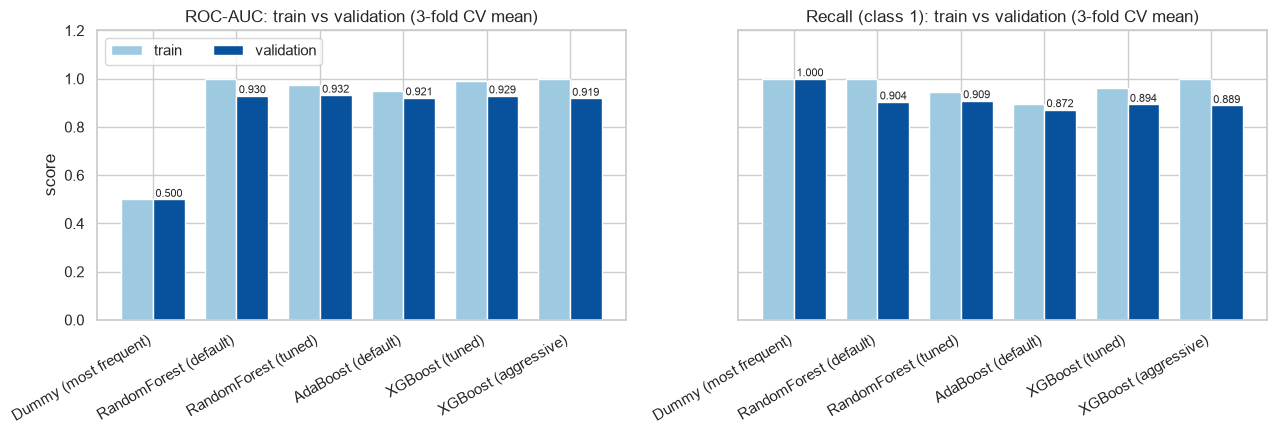

In [8]:
# Overfitting check: mean train vs validation score and their gap, per model
gap_rows = []
for name, r in part3_cv.items():
    row = {"model": name}
    for m in ("roc_auc", "recall", "accuracy"):
        row[f"train_{m}"] = r[f"train_{m}"].mean()
        row[f"val_{m}"] = r[f"test_{m}"].mean()
        row[f"gap_{m}"] = row[f"train_{m}"] - row[f"val_{m}"]
    gap_rows.append(row)
part3_gap = pd.DataFrame(gap_rows).set_index("model").round(3) + 0.0   # + 0.0 turns -0.0 into 0.0
display(part3_gap)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
x, w = np.arange(len(part3_gap)), 0.38
for ax, m, title in [(axes[0], "roc_auc", "ROC-AUC"), (axes[1], "recall", "Recall (class 1)")]:
    ax.bar(x - w / 2, part3_gap[f"train_{m}"], w, label="train", color="#9ecae1")
    ax.bar(x + w / 2, part3_gap[f"val_{m}"], w, label="validation", color="#08519c")
    for xi, v in zip(x, part3_gap[f"val_{m}"]):
        ax.text(xi + w / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x, part3_gap.index, rotation=30, ha="right")
    ax.set_title(f"{title}: train vs validation (3-fold CV mean)")
    ax.set_ylim(0, 1.2)
axes[0].set_ylabel("score"); axes[0].legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

### 3.4 Interpretation and guiding questions

**Comparison (validation, mean over the 3 shared folds; gap = train − validation ROC-AUC, from the two tables above)**

| Model | val ROC-AUC | val recall | val precision | val F1 | ROC-AUC gap |
|---|---|---|---|---|---|
| Dummy (most frequent) | 0.500 | 1.000 | 0.553 | 0.712 | 0.000 |
| RandomForest (default) | 0.930 ± 0.012 | 0.904 ± 0.040 | 0.856 | 0.879 | 0.070 |
| RandomForest (tuned) | **0.932 ± 0.013** | **0.909 ± 0.033** | 0.848 | 0.877 | 0.041 |
| AdaBoost (default) | 0.921 ± 0.014 | 0.872 ± 0.015 | 0.864 | 0.868 | 0.028 |
| XGBoost (tuned) | 0.929 ± 0.006 | 0.894 ± 0.033 | 0.863 | 0.878 | 0.062 |
| XGBoost (aggressive) | 0.919 ± 0.011 | 0.889 ± 0.016 | 0.856 | 0.872 | 0.081 |

All ensembles are far above the Dummy (ROC-AUC 0.500), whose recall of 1.000 comes only from predicting "disease" for everyone (precision 0.553). Among the real models, the top three (RF default, RF tuned, XGBoost tuned) lie within 0.003 ROC-AUC of each other, well inside the fold std of 0.006–0.013.

**Why can boosting outperform bagging?** Bagging (Random Forest) averages many deep, decorrelated trees: it mainly *reduces variance* but cannot remove bias shared by all trees. Boosting builds shallow trees sequentially, each one fitting the errors of the ensemble so far, so it *reduces bias* and can capture structure that averaging misses. **Here it did not outperform:** tuned XGBoost (0.929 ROC-AUC, 0.894 recall) is slightly below the tuned forest (0.932, 0.909), and default AdaBoost is lower still (0.921, 0.872). With only 734 training rows (two thirds of which are used per fold), a handful of features and noisy measurements (imputed Cholesterol zeros), bias is not the bottleneck: the forest's variance reduction is already enough, and boosting's extra fitting power mostly goes into the training folds.

**When can boosting overfit?** When each round is allowed to fit too much (large learning rate, deep trees, many rounds without early stopping) on small or noisy data: later rounds fit the residual *noise*, and unlike bagging nothing averages it away. Our numbers show this: the aggressive XGBoost (depth 5, learning rate 0.3) reaches train ROC-AUC 1.000 with validation 0.919 (gap 0.081), while the gentlest setting (depth 3, learning rate 0.05) has the smallest XGBoost gap (0.062) and the best validation score (0.929). In the 3.2 grid every setting except that one reached train ROC-AUC ≥ 0.999. AdaBoost shows the opposite end: its default weak learners give the smallest gap (0.028) but also lower validation scores, i.e. it is closer to underfitting.

**Did extra complexity help?** No. Fully grown forests (RF default: train ROC-AUC 1.000) validate at 0.930, versus 0.932 for the regularised forest, a difference inside the noise; regularisation mainly shrank the gap (0.070 → 0.041). Making XGBoost more aggressive lowered validation (0.929 → 0.919). And switching from bagging to the more elaborate boosting algorithms did not beat the forest.

**Final-model candidate for Part 5 (chosen on validation only): RandomForest (tuned)**, `max_depth=10, min_samples_leaf=5`, 300 trees, improved preprocessing. It has the highest validation ROC-AUC (0.932) and the highest validation recall of any non-dummy model (0.909, our primary metric), with a smaller train–validation gap than the default forest (0.041 vs 0.070). Caveats: its lead over RF default and XGBoost tuned is within the fold noise, its precision (0.848) is the lowest of the ensembles, and its score was selected on the same folds it was measured on, so it is slightly optimistic. XGBoost (tuned) is a reasonable runner-up. The untouched test set gives the honest estimate in Part 5.

## Part 4 – Class Imbalance and SMOTENC
**Requirements:** report the class ratio; one controlled experiment (same model with vs. without SMOTENC) in an `imblearn` pipeline; categoricals handled correctly; resampling only inside training folds; discuss whether it was needed.

### 4.1 Class ratio

In [9]:
# Class balance on the TRAINING split only (the test split stays locked)
counts = y_train.value_counts().sort_index()
class_ratio = pd.DataFrame({
    "label": ["0 = no heart disease", "1 = heart disease"],
    "count": counts.values,
    "share": (counts / counts.sum()).round(3).values,
}, index=counts.index.rename("class"))
display(class_ratio)
print(f"majority : minority = {counts.max()} : {counts.min()} = {counts.max() / counts.min():.2f} : 1"
      f"  (minority class = {counts.idxmin()})")

,label,count,share
class,,,
0,0 = no heart disease,328,0.447
1,1 = heart disease,406,0.553


majority : minority = 406 : 328 = 1.24 : 1  (minority class = 0)


**Class ratio.** The training split has 406 patients with heart disease (class 1, share 0.553) and 328 without (class 0, share 0.447), a majority : minority ratio of **1.24 : 1**. The **minority class is class 0 (no heart disease)**: the class we care most about detecting (class 1) is the *majority* here.

**What this means for SMOTENC.** With the default `sampling_strategy="auto"`, SMOTENC oversamples every class except the majority up to the majority count, so in each training fold it creates synthetic **healthy (class 0)** patients until both classes are equal (406 : 406 on the full training split). This is the opposite of the usual motivation for SMOTE: it gives the model *more* evidence for "no disease", which can only push predictions towards class 0, so if anything we should expect recall on class 1 to stay the same or drop, with precision possibly rising. The imbalance is also mild (1.24 : 1), so a large effect is not expected either way. Section 4.3 tests this in a controlled experiment.

### 4.2 SMOTENC pipeline

We use an `imblearn.pipeline.Pipeline` (not sklearn's), because only it accepts a *sampler* step; it calls the sampler during `fit` only, so resampling happens inside each training fold and never on validation (or test) data. The step order is forced by what SMOTENC needs:

1. **`num_prep`: impute and scale the numerics, keep categoricals un-encoded.** A `ColumnTransformer` applies Member 1's `build_numeric_pipeline("improved")` (zeros → NaN, `StandardScaler`, `KNNImputer` with a missingness indicator) to `NUM_COLS` and passes `CAT_COLS` through as their original labels. SMOTENC cannot handle NaN (so imputation must come first), and it finds nearest neighbours by distance (so numerics must be on a common scale, otherwise e.g. Cholesterol in mg/dl would dominate Age). `set_output(transform="pandas")` + `verbose_feature_names_out=False` keep column names, so SMOTENC can be told which columns are categorical by name.
2. **`smote`: SMOTENC** on `CAT_COLS + ["FastingBS", "missingindicator_Cholesterol"]` as categorical features. For each synthetic sample it *interpolates* the continuous columns between a minority sample and a neighbour, but sets each categorical column to the most frequent value among the neighbours, so it never invents labels like "half ASY, half NAP". `FastingBS` is a 0/1 flag listed among the numerics, and the missingness indicator is also 0/1; treating both as categorical stops SMOTENC from creating impossible fractional values. Ordinary SMOTE on one-hot columns would make exactly that mistake for every category.
3. **`encode`: one-hot encode `CAT_COLS`** *after* resampling (numerics pass through unchanged), so the model sees the same kind of features as in Part 3.
4. **`model`: the tuned Random Forest** from 3.1 (`max_depth=10, min_samples_leaf=5`, 300 trees, `random_state=SEED`).

For the controlled comparison in 4.3 the *same* pipeline is built with and without step 2, so SMOTENC is the only factor that changes.

In [10]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from imblearn.over_sampling import SMOTENC

SMOTE_CAT = CAT_COLS + ["FastingBS", "missingindicator_Cholesterol"]   # 0/1 columns too: no fractional values
rf_best_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}

def build_smote_pipeline(use_smote=True):
    """Same steps with or without SMOTENC -> only the sampler differs."""
    steps = [
        ("num_prep", ColumnTransformer([("num", build_numeric_pipeline("improved"), NUM_COLS),
                                        ("cat", "passthrough", CAT_COLS)],          # categoricals stay un-encoded
                                       verbose_feature_names_out=False).set_output(transform="pandas")),
    ]
    if use_smote:
        steps.append(("smote", SMOTENC(categorical_features=SMOTE_CAT, random_state=SEED)))
    steps += [
        ("encode", ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)],
                                     remainder="passthrough")),                    # one-hot AFTER resampling
        ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, **rf_best_params)),
    ]
    return ImbPipeline(steps)

smote_pipe, no_smote_pipe = build_smote_pipeline(True), build_smote_pipeline(False)
print("with SMOTENC:   ", list(smote_pipe.named_steps))
print("without SMOTENC:", list(no_smote_pipe.named_steps))

# --- Sanity check on the training split (inspection only; the CV experiment in 4.3 refits everything per fold)
Xp = clone(smote_pipe.named_steps["num_prep"]).fit_transform(X_train)
X_res, y_res = clone(smote_pipe.named_steps["smote"]).fit_resample(Xp, y_train)
print("\ncolumns seen by SMOTENC:", list(Xp.columns))
print("NaN before SMOTENC:", int(Xp.isna().sum().sum()))
print("class counts before:", y_train.value_counts().sort_index().to_dict(),
      "| after:", pd.Series(y_res).value_counts().sort_index().to_dict())
print("missingindicator_Cholesterol values after:", sorted(X_res["missingindicator_Cholesterol"].unique().tolist()))
print("FastingBS unique values after:", X_res["FastingBS"].nunique(), np.round(sorted(X_res["FastingBS"].unique()), 3))
for col in CAT_COLS:
    print(f"{col:15s} before: {sorted(X_train[col].unique())}  after: {sorted(X_res[col].unique())}")

with SMOTENC:    ['num_prep', 'smote', 'encode', 'model']
without SMOTENC: ['num_prep', 'encode', 'model']



columns seen by SMOTENC: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak', 'FastingBS', 'missingindicator_Cholesterol', 'Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
NaN before SMOTENC: 0
class counts before: {0: 328, 1: 406} | after: {0: 406, 1: 406}
missingindicator_Cholesterol values after: [0.0, 1.0]
FastingBS unique values after: 2 [-0.545  1.835]
Sex             before: ['F', 'M']  after: ['F', 'M']
ChestPainType   before: ['ASY', 'ATA', 'NAP', 'TA']  after: ['ASY', 'ATA', 'NAP', 'TA']
RestingECG      before: ['LVH', 'Normal', 'ST']  after: ['LVH', 'Normal', 'ST']
ExerciseAngina  before: ['N', 'Y']  after: ['N', 'Y']
ST_Slope        before: ['Down', 'Flat', 'Up']  after: ['Down', 'Flat', 'Up']


### 4.3 With vs. without SMOTENC

In [11]:
# Controlled experiment: identical pipeline, identical folds; the ONLY difference is the SMOTENC step
part4_cv = {
    "RF tuned, without SMOTENC": cross_validate(no_smote_pipe, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True),
    "RF tuned, with SMOTENC":    cross_validate(smote_pipe,    X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True),
}
part4_table = pd.DataFrame([summarize_cv(r, name) for name, r in part4_cv.items()]).set_index("model")
display(part4_table)

# Per-fold validation scores (same 3 folds for both rows)
per_fold = pd.concat({name: pd.DataFrame({m: r[f"test_{m}"] for m in ("recall", "precision", "accuracy", "roc_auc")})
                      for name, r in part4_cv.items()}, names=["model", "fold"]).round(3)
display(per_fold.unstack("model").swaplevel(axis=1).sort_index(axis=1))

# Proof that the sampler runs only during fit: one CV fold by hand
tr_idx, va_idx = next(CV.split(X_train, y_train))
X_tr, y_tr, X_va = X_train.iloc[tr_idx], y_train.iloc[tr_idx], X_train.iloc[va_idx]
fitted = clone(smote_pipe).fit(X_tr, y_tr)
_, y_tr_res = fitted.named_steps["smote"].fit_resample(fitted.named_steps["num_prep"].transform(X_tr), y_tr)
print(f"fold 1 training rows: {len(X_tr)} -> {len(y_tr_res)} after SMOTENC (class counts {pd.Series(y_tr_res).value_counts().sort_index().to_dict()})")
print(f"fold 1 validation rows: {len(X_va)} in -> {len(fitted.predict(X_va))} predictions (imblearn skips samplers in predict/transform)")

# Why "without SMOTENC" can differ from the 3.3 'RandomForest (tuned)' row: the encode step puts one-hot columns FIRST,
# Part 3 puts numerics first. Control: same no-SMOTENC pipeline with Part 3's column order.
order_ctrl = build_smote_pipeline(False)
order_ctrl.steps[1] = ("encode", ColumnTransformer([("num", "passthrough", NUM_COLS + ["missingindicator_Cholesterol"]),
                                                    ("onehot", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)]))
order_cv = cross_validate(order_ctrl, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)
pd.DataFrame([summarize_cv(part3_cv["RandomForest (tuned)"], "3.3 RF tuned (numerics first)"),
              summarize_cv(part4_cv["RF tuned, without SMOTENC"], "4.3 without SMOTENC (one-hot first)"),
              summarize_cv(order_cv, "4.3 without SMOTENC, numerics first")]).set_index("model")[["val_recall", "val_roc_auc", "val_precision"]]

,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc
model,,,,,,,,,,
"RF tuned, without SMOTENC",0.899 +/- 0.004,0.868 +/- 0.018,0.888 +/- 0.003,0.857 +/- 0.006,0.935 +/- 0.012,0.914 +/- 0.030,0.911 +/- 0.004,0.884 +/- 0.017,0.972 +/- 0.001,0.932 +/- 0.015
"RF tuned, with SMOTENC",0.907 +/- 0.010,0.860 +/- 0.017,0.904 +/- 0.006,0.862 +/- 0.016,0.931 +/- 0.015,0.889 +/- 0.016,0.917 +/- 0.009,0.875 +/- 0.015,0.973 +/- 0.001,0.932 +/- 0.016


model RF tuned, with SMOTENC                          RF tuned, without SMOTENC                         
                    accuracy precision recall roc_auc                  accuracy precision recall roc_auc
fold                                                                                                    
0                      0.857     0.853  0.897   0.937                     0.853     0.852  0.890   0.933
1                      0.841     0.848  0.867   0.911                     0.857     0.852  0.896   0.914
2                      0.881     0.884  0.904   0.949                     0.893     0.866  0.956   0.950

fold 1 training rows: 489 -> 540 after SMOTENC (class counts {0: 270, 1: 270})
fold 1 validation rows: 245 in -> 245 predictions (imblearn skips samplers in predict/transform)


,val_recall,val_roc_auc,val_precision
model,,,
3.3 RF tuned (numerics first),0.909 +/- 0.033,0.932 +/- 0.013,0.848 +/- 0.009
4.3 without SMOTENC (one-hot first),0.914 +/- 0.030,0.932 +/- 0.015,0.857 +/- 0.006
"4.3 without SMOTENC, numerics first",0.909 +/- 0.033,0.932 +/- 0.013,0.848 +/- 0.009


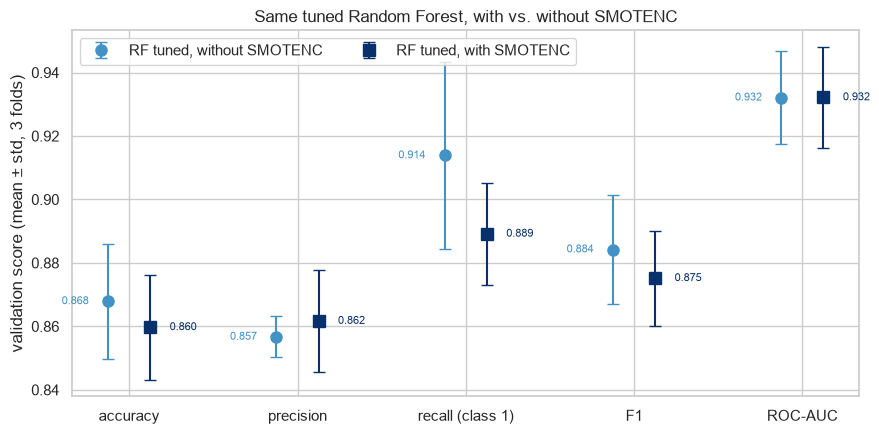

In [12]:
# Dot plot (not bars): the axis does not start at 0, so dots avoid exaggerating small differences
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(metrics))
for k, (name, color, marker) in enumerate([("RF tuned, without SMOTENC", "#4292c6", "o"),
                                           ("RF tuned, with SMOTENC", "#08306b", "s")]):
    r = part4_cv[name]
    means = np.array([r[f"test_{m}"].mean() for m in metrics])
    stds = np.array([r[f"test_{m}"].std() for m in metrics])
    xs = x + (k - 0.5) * 0.25
    ax.errorbar(xs, means, yerr=stds, fmt=marker, color=color, capsize=4, markersize=8, label=name)
    for xi, v in zip(xs, means):
        ax.annotate(f"{v:.3f}", (xi, v), textcoords="offset points", xytext=(14 if k else -14, 0),
                    ha="left" if k else "right", va="center", fontsize=8, color=color)
ax.set_xticks(x, ["accuracy", "precision", "recall (class 1)", "F1", "ROC-AUC"])
ax.set_ylabel("validation score (mean ± std, 3 folds)")
ax.set_title("Same tuned Random Forest, with vs. without SMOTENC")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

### 4.4 Interpretation

**Did SMOTENC help? No; it slightly hurt the metric we care about.** With the same tuned forest and the same folds, adding SMOTENC changed validation scores as follows (4.3 table):

| | without SMOTENC | with SMOTENC | change |
|---|---|---|---|
| recall (class 1) | 0.914 ± 0.030 | 0.889 ± 0.016 | −0.025 |
| precision | 0.857 ± 0.006 | 0.862 ± 0.016 | +0.005 |
| accuracy | 0.868 ± 0.018 | 0.860 ± 0.017 | −0.008 |
| F1 | 0.884 ± 0.017 | 0.875 ± 0.015 | −0.009 |
| ROC-AUC | 0.932 ± 0.015 | 0.932 ± 0.016 | 0.000 |

Per fold, recall dropped in two of the three folds (0.896 → 0.867 and 0.956 → 0.904) and rose slightly in one (0.890 → 0.897), so the direction is fairly consistent, although the mean change is within the fold std.

**Why.** The minority class here is class 0 (4.1), so SMOTENC's default strategy created synthetic **healthy** patients (fold 1: 489 → 540 training rows, 270 : 270). The forest then sees relatively more "no disease" evidence and predicts class 1 less often: fewer positives means lower recall and slightly higher precision. ROC-AUC is unchanged (0.932) because the *ranking* of patients barely moves; oversampling mostly acts like shifting the decision threshold, which ROC-AUC ignores by construction.

**Can recall improve while precision or accuracy worsens?** Yes, and this experiment shows the same trade-off in mirror image. Oversampling a class makes the model predict that class more often. Had the minority been the disease class, SMOTENC would push predictions towards class 1, usually raising recall while lowering precision, and accuracy can fall too. Here the oversampled class is the healthy one, so recall fell while precision rose (and accuracy fell slightly). Resampling moves the model along the precision–recall trade-off; it does not create new information.

**Was resampling needed? No.** The imbalance is mild (1.24 : 1) and the "minority" is not the class we prioritise; ranking quality (ROC-AUC) did not change, and recall got worse. If Part 5 needs more recall, lowering the decision threshold of the model without SMOTENC achieves the same trade-off directly and transparently, without synthetic patients. We therefore keep the model **without SMOTENC**.

**Note on the "without SMOTENC" row (0.914 recall vs 0.909 for RF tuned in 3.3).** The two pipelines apply identical preprocessing and the same forest; the only difference is that the 4.2 `encode` step puts the one-hot columns *before* the numerics. Random Forest picks random feature subsets by column position, so a different column order grows different trees. The control in 4.3 (same pipeline, numerics first) reproduces the 3.3 row exactly (recall 0.909, ROC-AUC 0.932, precision 0.848). The 0.005 recall difference is therefore pure random-seed variation. It is a useful yardstick: differences of this size between models are noise.

### Handoff to Member 3

**Recommended final-model candidate (chosen on validation only): `RandomForest (tuned)`**, the Part 3 pipeline `"pre"` = `build_preprocessor("improved")` → `"model"` = `RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=SEED, n_jobs=-1)`, **without SMOTENC**. Validation (3-fold CV on the training split): ROC-AUC 0.932 ± 0.013, recall 0.909 ± 0.033, precision 0.848 ± 0.009, F1 0.877 ± 0.020, train–validation ROC-AUC gap 0.041. Runner-up: `XGBoost (tuned)` (`max_depth=3, learning_rate=0.05`, 200 rounds; val ROC-AUC 0.929, recall 0.894). Their difference is within fold noise (see 3.4 and the column-order note in 4.4). SMOTENC is not recommended (4.4).

**Objects to use (all defined above):**
- `final_model = rf_search.best_estimator_`: already refit by `GridSearchCV` on the full `X_train` (cell above), so Part 5 can evaluate it once on the test set without refitting. `xgb_search.best_estimator_` is the runner-up, also refit on `X_train`.
- Tables: `rf_grid_table`, `xgb_grid_table` (3.1/3.2 grids), `part3_table` (validation, all Part 3 models), `part3_gap` (train vs validation), `part4_table` (with vs without SMOTENC).
- Raw `cross_validate` results: `part3_cv`, `part4_cv` (dicts of arrays, one value per fold).
- File: `member2_cv_results.csv` (one row per model/setting, numeric `train_*` / `val_*` mean and std).

**Test set untouched.** `X_test` / `y_test` are only loaded by `load_and_split` and their shape printed in cell 4; no model in this section was fitted or scored on them. The single final evaluation is Member 3's (Part 5).

**For SHAP (Part 6):** use `final_model.named_steps["model"]` with `shap.TreeExplainer`, pass it `final_model.named_steps["pre"].transform(X)`, and label the columns with `final_model.named_steps["pre"].get_feature_names_out()` (the 21 names printed above, e.g. `num__missingindicator_Cholesterol`, `cat__ST_Slope_Up`). If false negatives are especially costly, Part 5 can lower the decision threshold of this model instead of resampling.

In [13]:
# Save every CV result of this section (numeric mean/std per metric, train and validation) for Member 3
def cv_row(section, model, raw):
    row = {"section": section, "model": model}
    for m in SCORING:
        for split, label in (("train", "train"), ("test", "val")):
            row[f"{label}_{m}_mean"] = raw[f"{split}_{m}"].mean()
            row[f"{label}_{m}_std"] = raw[f"{split}_{m}"].std()
    return row

def grid_rows(section, search):
    res, rows = search.cv_results_, []
    for i, p in enumerate(res["params"]):
        name = ", ".join(f"{k.replace('model__', '')}={v}" for k, v in p.items())
        raw = {f"{s}_{m}": np.array([res[f"split{f}_{s}_{m}"][i] for f in range(CV.get_n_splits())])
               for m in SCORING for s in ("train", "test")}
        rows.append(cv_row(section, name, raw))
    return rows

all_rows = grid_rows("3.1 RF grid", rf_search) + grid_rows("3.2 XGB grid", xgb_search)
all_rows += [cv_row("3.3 comparison", name, r) for name, r in part3_cv.items()]
all_rows += [cv_row("4.3 SMOTENC", name, r) for name, r in part4_cv.items()]
all_rows.append(cv_row("4.3 SMOTENC (column-order control)", "RF tuned, without SMOTENC, numerics first", order_cv))
member2_cv_results = pd.DataFrame(all_rows)
member2_cv_results.to_csv("member2_cv_results.csv", index=False)
print("saved member2_cv_results.csv:", member2_cv_results.shape)
display(member2_cv_results[["section", "model", "val_recall_mean", "val_roc_auc_mean"]].round(3))

# Handoff check: the final candidate is already refit on the full training split, and SHAP feature names resolve
final_model = rf_search.best_estimator_
print("final candidate steps:", list(final_model.named_steps), "| params:", rf_search.best_params_)
feature_names = final_model.named_steps["pre"].get_feature_names_out()
print(len(feature_names), "features:", list(feature_names))

saved member2_cv_results.csv: (21, 22)


,section,model,val_recall_mean,val_roc_auc_mean
0,3.1 RF grid,"max_depth=None, min_samples_leaf=1",0.904,0.930
1,3.1 RF grid,"max_depth=None, min_samples_leaf=5",0.909,0.932
2,3.1 RF grid,"max_depth=5, min_samples_leaf=1",0.909,0.932
3,3.1 RF grid,"max_depth=5, min_samples_leaf=5",0.909,0.932
4,3.1 RF grid,"max_depth=10, min_samples_leaf=1",0.892,0.930
5,3.1 RF grid,"max_depth=10, min_samples_leaf=5",0.909,0.932
6,3.2 XGB grid,"learning_rate=0.05, max_depth=3",0.894,0.929
7,3.2 XGB grid,"learning_rate=0.05, max_depth=5",0.892,0.919
8,3.2 XGB grid,"learning_rate=0.1, max_depth=3",0.887,0.922
9,3.2 XGB grid,"learning_rate=0.1, max_depth=5",0.887,0.921


final candidate steps: ['pre', 'model'] | params: {'model__max_depth': 10, 'model__min_samples_leaf': 5}
21 features: ['num__Age', 'num__RestingBP', 'num__Cholesterol', 'num__MaxHR', 'num__Oldpeak', 'num__FastingBS', 'num__missingindicator_Cholesterol', 'cat__Sex_F', 'cat__Sex_M', 'cat__ChestPainType_ASY', 'cat__ChestPainType_ATA', 'cat__ChestPainType_NAP', 'cat__ChestPainType_TA', 'cat__RestingECG_LVH', 'cat__RestingECG_Normal', 'cat__RestingECG_ST', 'cat__ExerciseAngina_N', 'cat__ExerciseAngina_Y', 'cat__ST_Slope_Down', 'cat__ST_Slope_Flat', 'cat__ST_Slope_Up']
